<a href="https://colab.research.google.com/github/Amyerm/ClassFiles/blob/main/Clases_No_Balanceadas%2C_Data_Leakage_(Pipeline)_y_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejercicios sobre Clases No Balanceadas, Data Leakage (Pipeline) y SVM
**Objetivo**
Aplicar técnicas de aprendizaje automático para el tratamiento de clases no balanceadas utilizando un problema de clasificación real.
---


---
## 1. Carga y análisis exploratorio de datos

In [24]:
# Importar bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [26]:
# Cargar el dataset

df = pd.read_csv("compustat.csv")

df.head()

,idx,at0,at1,at2,at3,at4,at5,at6,at7,at8,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,...,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,...,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,...,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,...,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,...,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


In [27]:
# Separar variables predictoras y objetivo

X = df.drop(columns=["idx", "label"])
y = df["label"]

print("Dimensiones:", df.shape)
print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.name)

Dimensiones: (13657, 22)
Variables predictoras: (13657, 20)
Variable objetivo: label


label
0    13137
1      520
Name: count, dtype: int64


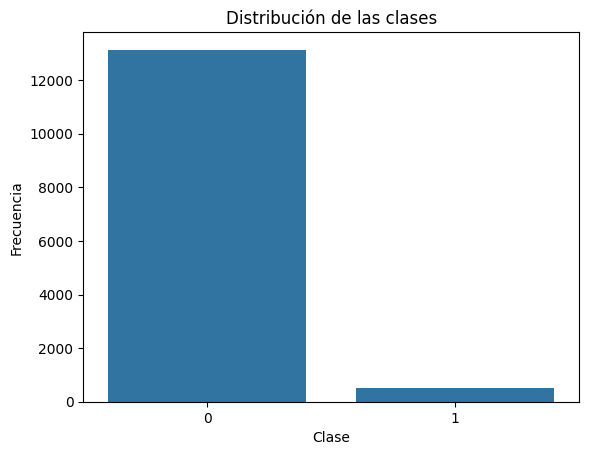

In [28]:
# Distribución de clases

print(y.value_counts())

sns.countplot(data=df, x="label")

plt.title("Distribución de las clases")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.show()

El conjunto de datos presenta un desbalance importante entre las clases. La clase 0 contiene 13,137 registros, lo que representa aproximadamente el 96.19% del total, mientras que la clase 1 solamente tiene 520 registros, equivalentes al 3.81%.

Esta diferencia puede provocar que el modelo favorezca a la clase mayoritaria y tenga dificultades para identificar los casos de la clase 1. Es importante comparar métodos de balanceo y utilizar métricas adicionales al Accuracy.

1.1 Diagramas de densidad KDE de los atributos 5 y 13

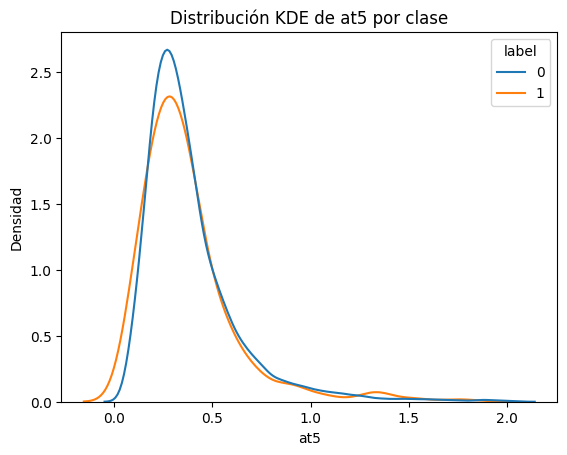

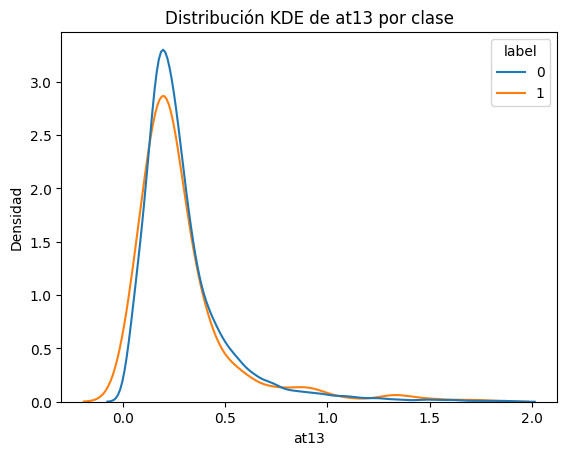

In [29]:
# Diagramas KDE de los atributos 5 y 13

for atributo in ["at5", "at13"]:

    # Limitar los valores extremos para visualizar mejor
    minimo = df[atributo].quantile(0.01)
    maximo = df[atributo].quantile(0.99)

    datos_grafica = df[df[atributo].between(minimo, maximo)]

    sns.kdeplot(
        data=datos_grafica,
        x=atributo,
        hue="label",
        common_norm=False
    )

    plt.title("Distribución KDE de " + atributo + " por clase")
    plt.xlabel(atributo)
    plt.ylabel("Densidad")
    plt.show()

En los diagramas KDE de at5 y at13 se observa que las distribuciones de ambas clases son bastante similares, las curvas se encuentran muy superpuestas. En los dos atributos, la mayor concentración de valores está en la parte baja y se observa una cola hacia la derecha. Estos atributos no parecen mostrar una separación muy clara entre las clases.

---
## 2. Modelo Base

2.1 Crear el Pipeline

In [30]:
# Modelo base con SVM

from sklearn.pipeline import Pipeline

modelo_base = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

modelo_base

Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC())])

2.2 Entrenar y evaluar con validación cruzada

In [31]:
# Validación cruzada estratificada

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Predicciones del modelo base
pred_base = cross_val_predict(
    modelo_base,
    X,
    y,
    cv=cv
)

2.3 Calcular las métricas

In [32]:
# Evaluación del modelo base

print("Accuracy:", round(accuracy_score(y, pred_base), 3))
print("Precision:", round(precision_score(y, pred_base, zero_division=0), 3))
print("Recall:", round(recall_score(y, pred_base, zero_division=0), 3))
print("F1-score:", round(f1_score(y, pred_base, zero_division=0), 3))

Accuracy: 0.962
Precision: 1.0
Recall: 0.008
F1-score: 0.015


2.4 Mostrar la matriz de confusión

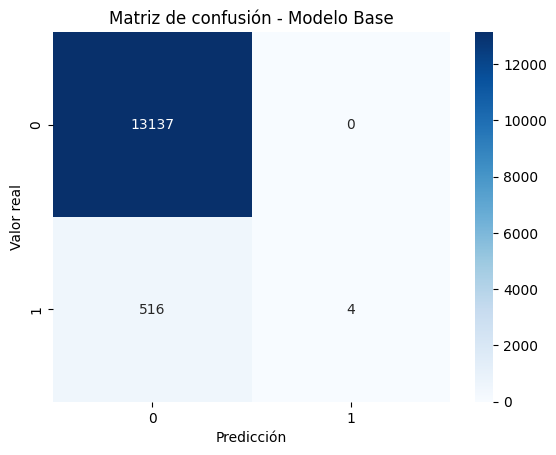

In [33]:
# Matriz de confusión del modelo base

matriz_base = confusion_matrix(y, pred_base)

sns.heatmap(
    matriz_base,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matriz de confusión - Modelo Base")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

El modelo base obtuvo un Accuracy de aproximadamente 0.962, lo que a primera vista parece un buen resultado. Al revisar las demás métricas se observa que el Recall de la clase 1 es de apenas 0.008 y el F1-score de 0.015.

En la matriz de confusión se observa que el modelo clasificó correctamente todos los registros de la clase 0, pero solamente identificó 4 de los 520 registros de la clase 1. El modelo favorece principalmente a la clase mayoritaria debido al desbalance de los datos. El Accuracy por sí solo no es suficiente para evaluar este problema, ya que puede mostrar un resultado alto aunque el modelo tenga dificultades para detectar la clase minoritaria.

---
## 3. Tratamiento de Clases No Balanceadas

3.1 Importar las bibliotecas

In [34]:
!pip install imbalanced-learn -q

In [35]:
# Bibliotecas para el balanceo

from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection
from imblearn.pipeline import Pipeline as ImbPipeline

3.2 Preparar una partición para visualizar el balanceo

In [36]:
# Obtener una partición de entrenamiento

train_idx, test_idx = next(cv.split(X, y))

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

# Escalar los datos de entrenamiento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

print("Distribución original:")
print(y_train.value_counts())

Distribución original:
label
0    10509
1      416
Name: count, dtype: int64


3.3 Aplicar SMOTEENN

In [37]:
# Aplicar SMOTEENN

smoteenn = SMOTEENN(random_state=42)

X_smote, y_smote = smoteenn.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución después de SMOTEENN:")
print(pd.Series(y_smote).value_counts())

Distribución después de SMOTEENN:
label
1    10470
0     9341
Name: count, dtype: int64


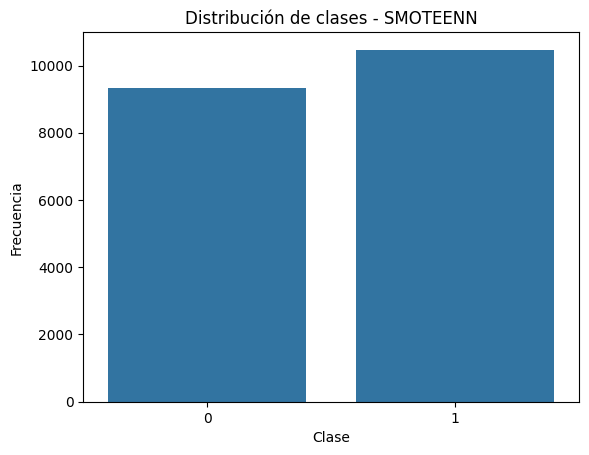

In [38]:
# Distribución de clases con SMOTEENN

sns.countplot(x=y_smote)

plt.title("Distribución de clases - SMOTEENN")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.show()

3.4 Aplicar One-Sided Selection

In [39]:
# Aplicar One-Sided Selection

oss = OneSidedSelection(random_state=42)

X_oss, y_oss = oss.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución después de One-Sided Selection:")
print(pd.Series(y_oss).value_counts())

Distribución después de One-Sided Selection:
label
0    10427
1      416
Name: count, dtype: int64


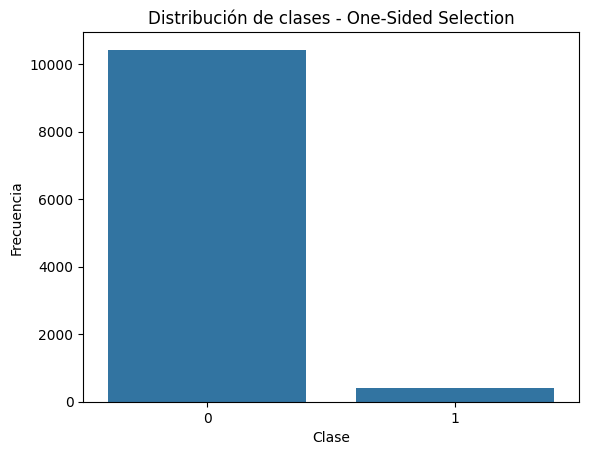

In [40]:
# Distribución de clases con One-Sided Selection

sns.countplot(x=y_oss)

plt.title("Distribución de clases - One-Sided Selection")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.show()

3.5 Entrenar el SVM con SMOTEENN

In [41]:
# Modelo SVM con SMOTEENN

modelo_smoteenn = ImbPipeline([
    ("scaler", StandardScaler()),
    ("balanceo", SMOTEENN(random_state=42)),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

pred_smoteenn = cross_val_predict(
    modelo_smoteenn,
    X,
    y,
    cv=cv
)

3.6 Entrenar el SVM con One-Sided Selection

In [42]:
# Modelo SVM con One-Sided Selection

modelo_oss = ImbPipeline([
    ("scaler", StandardScaler()),
    ("balanceo", OneSidedSelection(random_state=42)),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

pred_oss = cross_val_predict(
    modelo_oss,
    X,
    y,
    cv=cv
)

Al aplicar SMOTEENN se observa un cambio importante en la distribución de las clases. La clase minoritaria pasó de 416 a 10,470 registros, mientras que la clase mayoritaria disminuyó a 9,341. Esto permitió obtener una distribución mucho más equilibrada.

Con One-Sided Selection solamente se redujeron algunos registros de la clase mayoritaria, pasando de 10,509 a 10,427, mientras que la clase minoritaria se mantuvo en 416. Este método no logró reducir de manera importante el desbalance en este caso.

Estos resultados muestran que SMOTEENN tuvo un mayor efecto sobre la distribución de los datos, aunque todavía es necesario evaluar el desempeño de los modelos para determinar cuál método ofrece mejores resultados de clasificación.

---
## 4. Entrenamiento y Evaluación del Modelo

4.1 Verificar los modelos utilizados

In [43]:
# Modelos utilizados en la evaluación

print("Modelo Base:")
print(modelo_base)

print("\nModelo con SMOTEENN:")
print(modelo_smoteenn)

print("\nModelo con One-Sided Selection:")
print(modelo_oss)

print("\nNúmero de folds:", cv.n_splits)

Modelo Base:
Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC())])

Modelo con SMOTEENN:
Pipeline(steps=[('scaler', StandardScaler()),
                ('balanceo', SMOTEENN(random_state=42)), ('svm', SVC())])

Modelo con One-Sided Selection:
Pipeline(steps=[('scaler', StandardScaler()),
                ('balanceo', OneSidedSelection(random_state=42)),
                ('svm', SVC())])

Número de folds: 5


4.2 Explicación del procedimiento

Para evaluar los modelos se utilizó validación cruzada estratificada con 5 particiones, conservando aproximadamente la proporción de ambas clases en cada una.

Se utilizó Pipeline para integrar el escalado de datos y el entrenamiento del SVM con kernel RBF. En los modelos con SMOTEENN y One-Sided Selection también se incluyó el balanceo dentro del Pipeline, de manera que solamente se aplicara a los datos de entrenamiento de cada partición.

Esto permite evitar data leakage y comparar los tres modelos bajo las mismas condiciones.

---
## 5. Evaluación de Resultados

5.1 Calcular las métricas de los tres modelos

In [44]:
# Comparación de métricas

modelos = {
    "Base": pred_base,
    "SMOTEENN": pred_smoteenn,
    "One-Sided Selection": pred_oss
}

resultados = []

for nombre, pred in modelos.items():
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1-score": f1_score(y, pred, zero_division=0)
    })

tabla_resultados = pd.DataFrame(resultados)

tabla_resultados.round(3)

,Modelo,Accuracy,Precision,Recall,F1-score
0,Base,0.962,1.000,0.008,0.015
1,SMOTEENN,0.811,0.144,0.800,0.244
2,One-Sided Selection,0.962,0.750,0.012,0.023


5.2 Mostrar las matrices de confusión

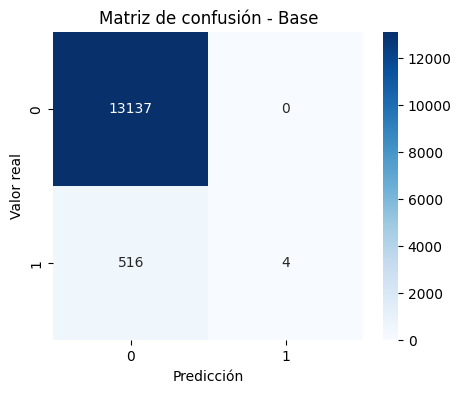

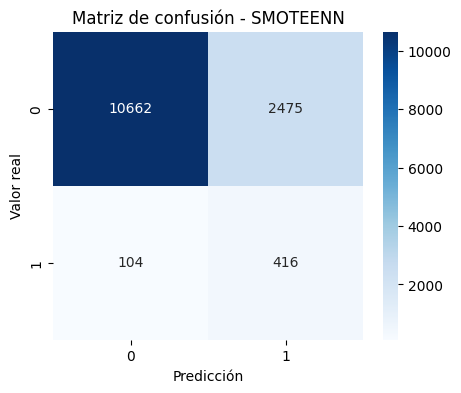

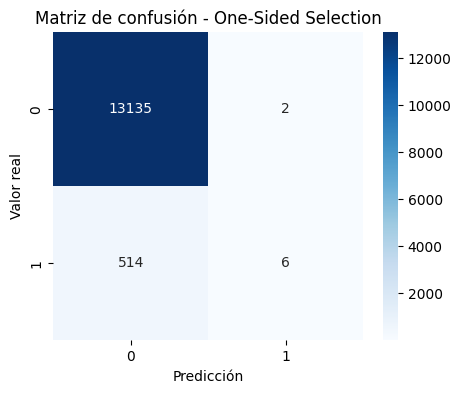

In [45]:
# Matrices de confusión

for nombre, pred in modelos.items():
    matriz = confusion_matrix(y, pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title("Matriz de confusión - " + nombre)
    plt.xlabel("Predicción")
    plt.ylabel("Valor real")
    plt.show()

5.3 Crear una gráfica comparativa de métricas

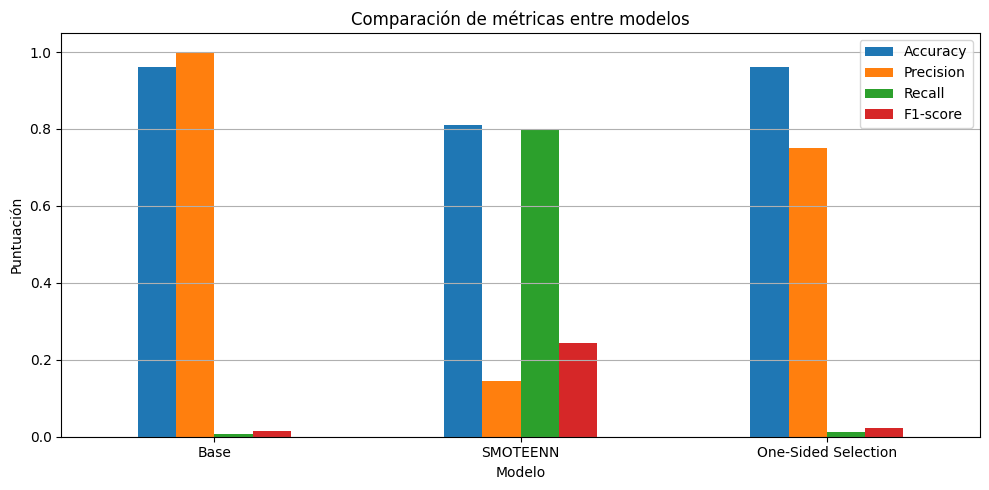

In [46]:
# Gráfica comparativa de métricas

tabla_resultados.set_index("Modelo")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Comparación de métricas entre modelos")
plt.xlabel("Modelo")
plt.ylabel("Puntuación")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

5.4 ¿Es suficiente Accuracy para evaluar este problema?

No, Accuracy por sí solo no es suficiente para evaluar este problema debido al desbalance de las clases. En el modelo base se obtuvo un Accuracy de aproximadamente 0.962, pero el Recall de la clase minoritaria fue de apenas 0.008.

Aunque el modelo clasificó correctamente la mayoría de los registros, solamente logró identificar 4 de los 520 casos de la clase 1. Es importante considerar Precision, Recall, F1-score y la matriz de confusión para evaluar qué tan bien se identifican los casos de la clase minoritaria.

**Comparación de los modelos**

Al comparar los tres modelos, se observa que el modelo base obtuvo un Accuracy alto de 0.962, pero prácticamente no logró identificar los casos de la clase minoritaria.

Con SMOTEENN, el Accuracy disminuyó a 0.811, pero el Recall aumentó considerablemente hasta 0.800 y el F1-score llegó a 0.244. El modelo logró detectar muchos más casos de la clase 1, aunque también generó una cantidad importante de falsos positivos. One-Sided Selection obtuvo resultados muy parecidos al modelo base, con un Recall de apenas 0.012 y un F1-score de 0.023. Por lo tanto, SMOTEENN fue el método que mostró una mayor mejora en la detección de la clase minoritaria, aunque todavía presenta limitaciones en Precision.

---
## 6. Discusión y Conclusiones

**¿Cuál fue el impacto del desbalance sobre el desempeño del modelo?**

El desbalance afectó principalmente la capacidad del modelo para identificar la clase minoritaria. En el modelo base se obtuvo un Accuracy de 0.962, pero el Recall fue de apenas 0.008, ya que solamente identificó 4 de los 520 casos de la clase 1. Un Accuracy alto no siempre significa que el modelo tenga un buen desempeño, especialmente cuando una clase tiene muchos más registros que la otra.

**¿Qué diferencias se observaron entre SMOTEENN y One-Sided Selection?**

SMOTEENN logró equilibrar mucho más las clases al generar nuevos registros de la clase minoritaria y eliminar algunos de la mayoritaria. Esto permitió aumentar el Recall hasta 0.800, aunque también produjo más falsos positivos y una Precision de 0.144.

One-Sided Selection solamente eliminó una pequeña cantidad de registros de la clase mayoritaria, por lo que el desbalance prácticamente se mantuvo. Su Recall fue de 0.012, muy similar al del modelo base, la mejora fue bastante limitada.

**¿Qué método produjo los mejores resultados y por qué?**

De los métodos evaluados, SMOTEENN obtuvo los mejores resultados para detectar la clase minoritaria, ya que alcanzó un Recall de 0.800 y un F1-score de 0.244, superiores a los otros dos modelos. Aunque su Accuracy disminuyó a 0.811, logró identificar 416 de los 520 casos de la clase 1.

También generó 2,475 falsos positivos, por lo que todavía tiene limitaciones. SMOTEENN fue la mejor opción en esta actividad si lo más importante es detectar los casos de la clase minoritaria, aunque sería necesario mejorar su Precision para obtener un modelo más equilibrado.